In [316]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [317]:
data = pd.read_csv("dataset.csv")

In [318]:
df = data.copy()

In [319]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [320]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [321]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [322]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [323]:
df.shape

(7043, 21)

In [324]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [325]:
blank_values = (
    df.astype(str)
    .apply(lambda x: x.str.strip().eq(""))
    .sum()
)

print(blank_values)

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [326]:
df["TotalCharges"] = (
    df["TotalCharges"]
    .replace(r"^\s*$", "0", regex=True)
)

In [327]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [328]:
blank_values = (
    df.astype(str)
    .apply(lambda x: x.str.strip().eq(""))
    .sum()
)

print(blank_values)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [329]:
df.duplicated().sum()

np.int64(0)

In [330]:
df['customerID'].duplicated().sum()

np.int64(0)

In [331]:
for col in df.select_dtypes(include="object").columns:

    spaces = (
        df[col].astype(str) !=
        df[col].astype(str).str.strip()
    )

    print(f"\nColumn: {col}")
    print("Extra spaces:", spaces.sum())


Column: customerID
Extra spaces: 0

Column: gender
Extra spaces: 0

Column: Partner
Extra spaces: 0

Column: Dependents
Extra spaces: 0

Column: PhoneService
Extra spaces: 0

Column: MultipleLines
Extra spaces: 0

Column: InternetService
Extra spaces: 0

Column: OnlineSecurity
Extra spaces: 0

Column: OnlineBackup
Extra spaces: 0

Column: DeviceProtection
Extra spaces: 0

Column: TechSupport
Extra spaces: 0

Column: StreamingTV
Extra spaces: 0

Column: StreamingMovies
Extra spaces: 0

Column: Contract
Extra spaces: 0

Column: PaperlessBilling
Extra spaces: 0

Column: PaymentMethod
Extra spaces: 0

Column: Churn
Extra spaces: 0


C:\Users\Acer\AppData\Local\Temp\ipykernel_13352\3612078833.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [332]:
for col in df.select_dtypes(include='object').columns:
    print("Column" , col)
    print(df[col].unique())

Column customerID
<StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str
Column gender
<StringArray>
['Female', 'Male']
Length: 2, dtype: str
Column Partner
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
Column Dependents
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
Column PhoneService
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
Column MultipleLines
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
Column InternetService
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
Column OnlineSecurity
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Column OnlineBackup
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
Column DevicePr

C:\Users\Acer\AppData\Local\Temp\ipykernel_13352\555902241.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [333]:
for col in df.select_dtypes(include=["object", "string"]).columns:

    print("\nColumn:", col)

    if col != "customerID":
        print(df[col].dropna().unique().tolist())


Column: customerID

Column: gender
['Female', 'Male']

Column: Partner
['Yes', 'No']

Column: Dependents
['No', 'Yes']

Column: PhoneService
['No', 'Yes']

Column: MultipleLines
['No phone service', 'No', 'Yes']

Column: InternetService
['DSL', 'Fiber optic', 'No']

Column: OnlineSecurity
['No', 'Yes', 'No internet service']

Column: OnlineBackup
['Yes', 'No', 'No internet service']

Column: DeviceProtection
['No', 'Yes', 'No internet service']

Column: TechSupport
['No', 'Yes', 'No internet service']

Column: StreamingTV
['No', 'Yes', 'No internet service']

Column: StreamingMovies
['No', 'Yes', 'No internet service']

Column: Contract
['Month-to-month', 'One year', 'Two year']

Column: PaperlessBilling
['Yes', 'No']

Column: PaymentMethod
['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']

Column: Churn
['No', 'Yes']


In [334]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [335]:
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


In [336]:
# df.to_csv("Cleaned.csv", index=False)

# print("Cleaned data saved successfully!")

In [337]:
df["gender"].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

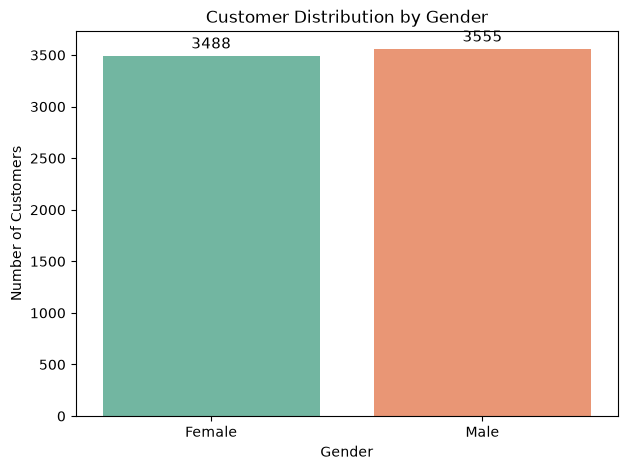

In [338]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="gender",
    hue="gender",
    palette="Set2",
    legend=False
)


for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=11)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

In [339]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [340]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

churn_percentage

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

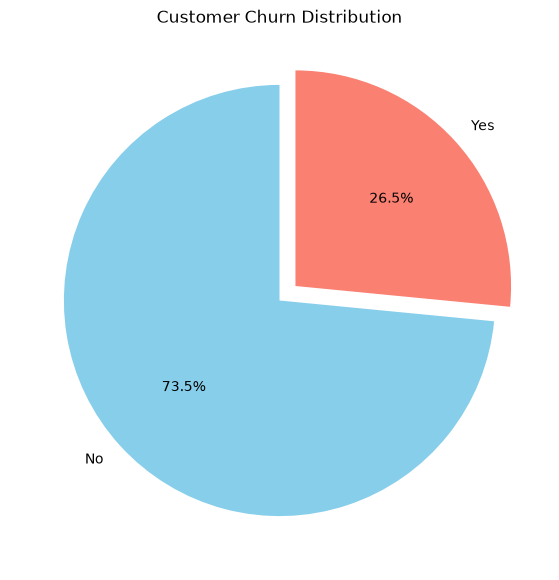

In [341]:
plt.figure(figsize=(7, 7))

churn_counts = df["Churn"].value_counts()

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["skyblue", "salmon"],
    explode=(0, 0.1)
)

plt.title("Customer Churn Distribution")

plt.show()

In [342]:
total_customers = len(df)

churned_customers = (df["Churn"] == "Yes").sum()

churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Churn Rate: 26.54 %


In [343]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [344]:
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


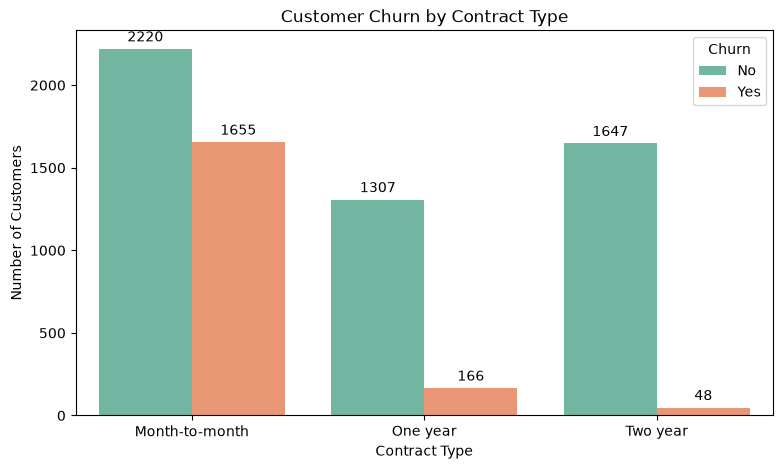

In [345]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    palette="Set2"
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.show()

In [346]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


<Figure size 900x500 with 0 Axes>

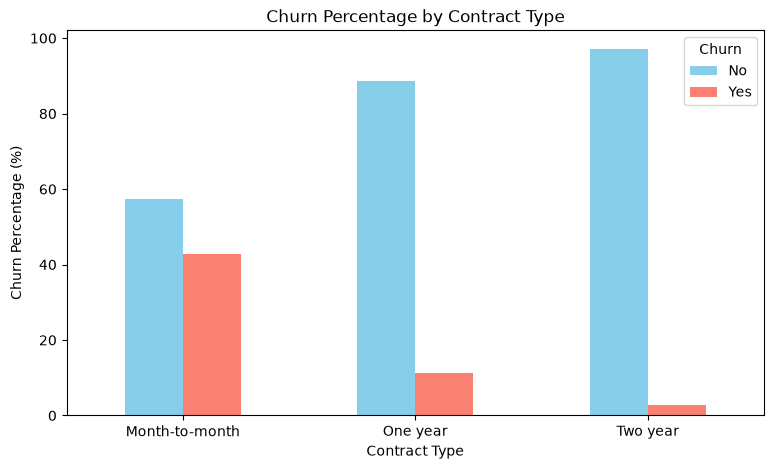

In [347]:
plt.figure(figsize=(9, 5))

ax = contract_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["skyblue", "salmon"]
)

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

In [348]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

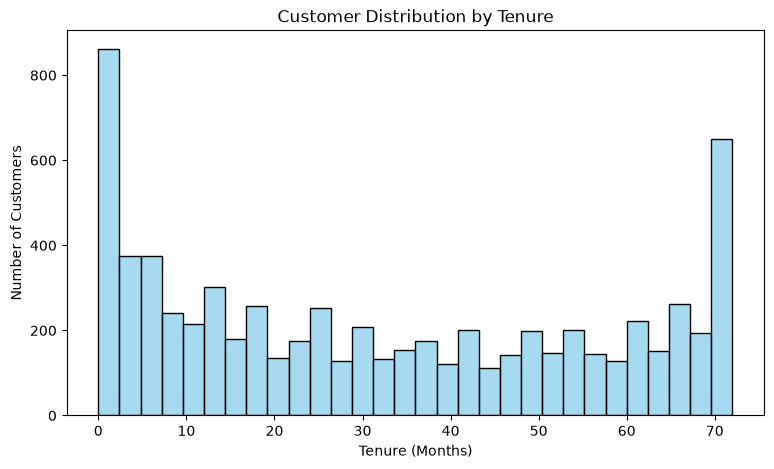

In [349]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    bins=30,
    color="skyblue",
    edgecolor="black"
)

plt.title("Customer Distribution by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

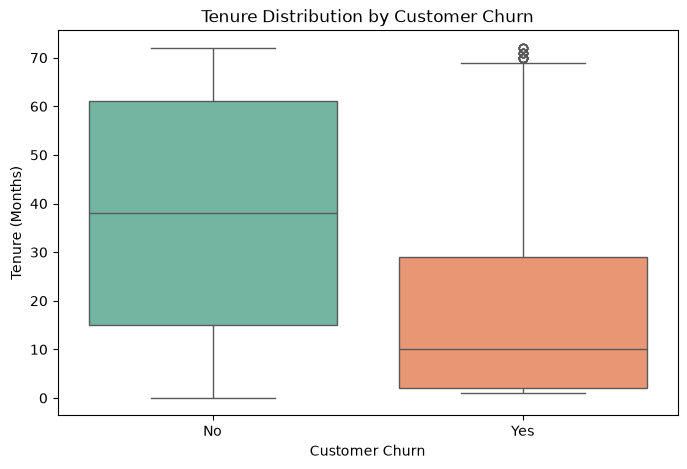

In [350]:
plt.figure(figsize=(8, 5))

ax = sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Tenure Distribution by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [351]:
tenure_analysis = df.groupby("Churn")["tenure"].mean()

print(tenure_analysis)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


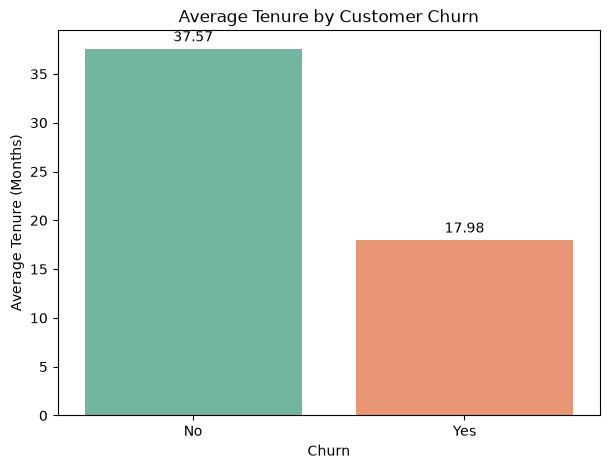

In [352]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=tenure_analysis.index,
    y=tenure_analysis.values,
    hue=tenure_analysis.index,
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Average Tenure by Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Average Tenure (Months)")

plt.show()

In [353]:
df["MonthlyCharges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

In [354]:
monthly_analysis = df.groupby("Churn")["MonthlyCharges"].mean()

print(monthly_analysis)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


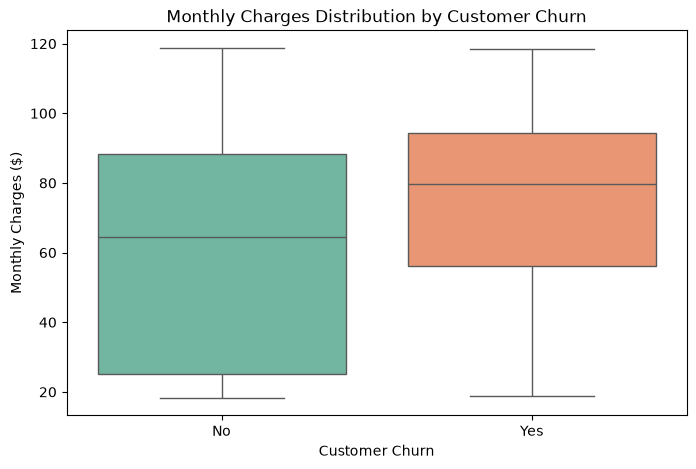

In [355]:
plt.figure(figsize=(8, 5))

ax = sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges Distribution by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges ($)")

plt.show()

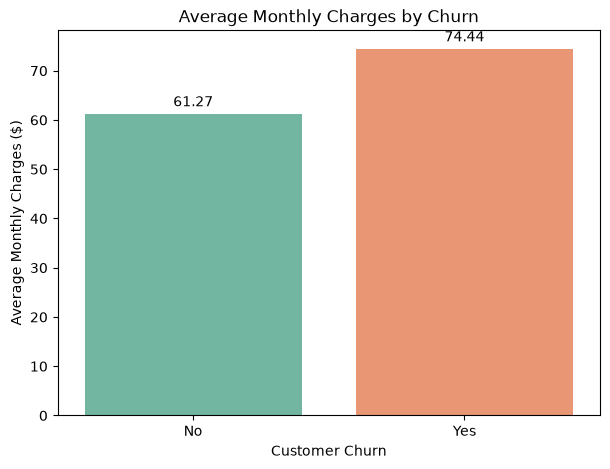

In [356]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=monthly_analysis.index,
    y=monthly_analysis.values,
    hue=monthly_analysis.index,
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Average Monthly Charges by Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Average Monthly Charges ($)")

plt.show()

In [357]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [358]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"]
)

internet_churn

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


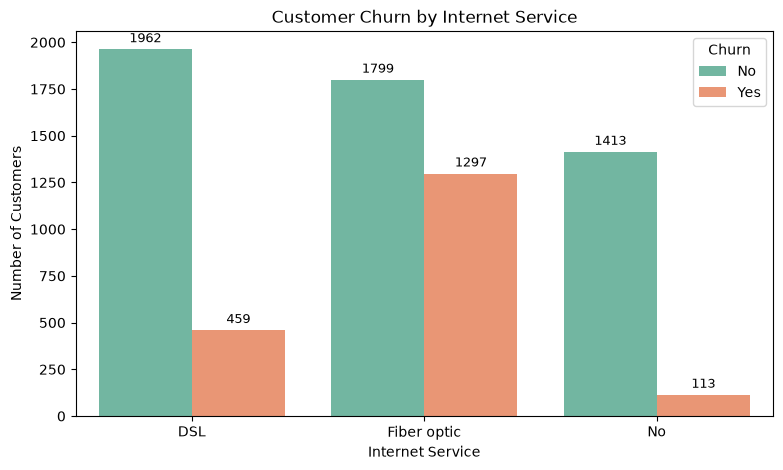

In [359]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn",
    palette="Set2"
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.show()

In [360]:
internet_churn_percentage = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

internet_churn_percentage

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


<Figure size 900x500 with 0 Axes>

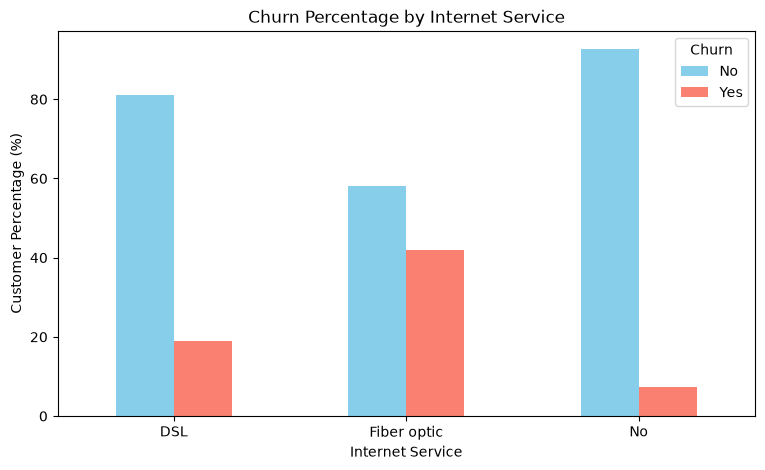

In [361]:
plt.figure(figsize=(9, 5))

ax = internet_churn_percentage.plot(
    kind="bar",
    figsize=(9, 5),
    color=["skyblue", "salmon"]
)

plt.title("Churn Percentage by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Customer Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

In [362]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [363]:
payment_churn =  pd.crosstab(
    df['PaymentMethod'],
    df['Churn']
)

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


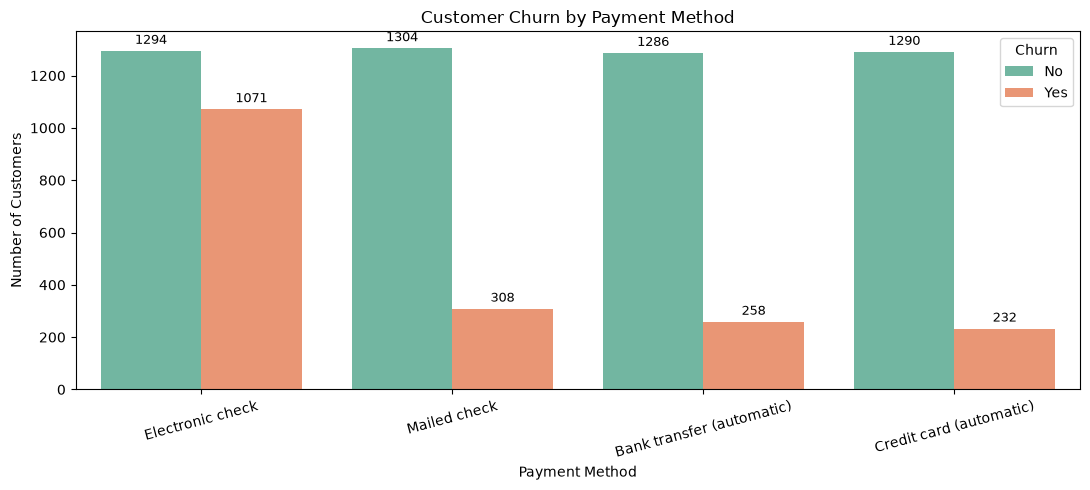

In [364]:
plt.figure(figsize=(11, 5))

ax = sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn",
    palette="Set2"
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.legend(title="Churn")

plt.tight_layout()
plt.show()

In [365]:
payment_churn_percentage = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn_percentage.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


<Figure size 1100x500 with 0 Axes>

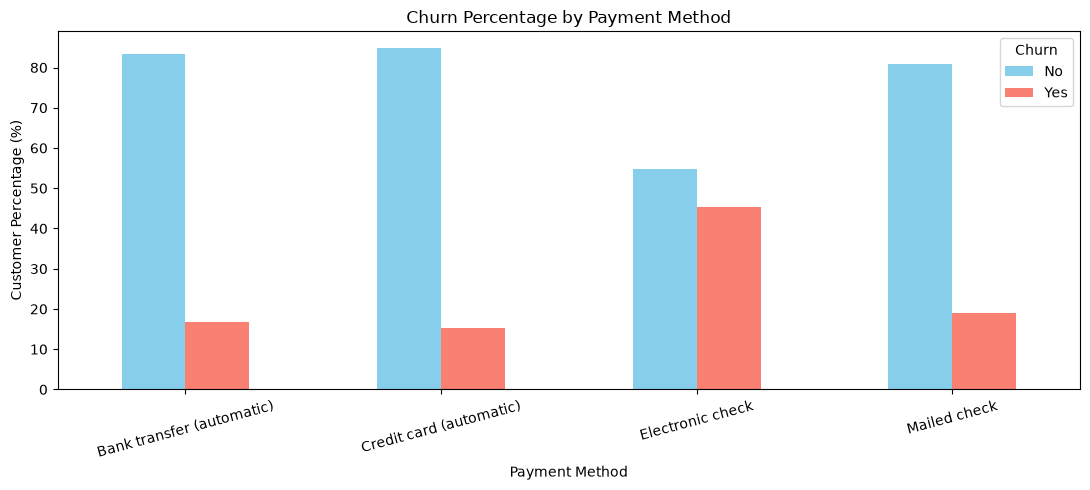

In [366]:
plt.figure(figsize=(11, 5))

ax = payment_churn_percentage.plot(
    kind="bar",
    figsize=(11, 5),
    color=["skyblue", "salmon"]
)

plt.title("Churn Percentage by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Customer Percentage (%)")
plt.xticks(rotation=15)
plt.legend(title="Churn")

plt.tight_layout()
plt.show()

In [367]:
df["SeniorCitizen"].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [369]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"]
)

senior_churn


Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


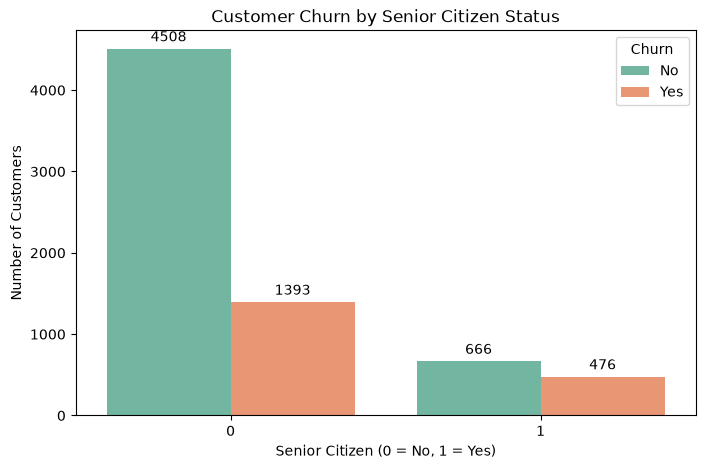

In [370]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="Churn",
    palette="Set2"
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.show()

In [371]:
senior_churn_percentage = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print(senior_churn_percentage.round(2))

Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68


<Figure size 800x500 with 0 Axes>

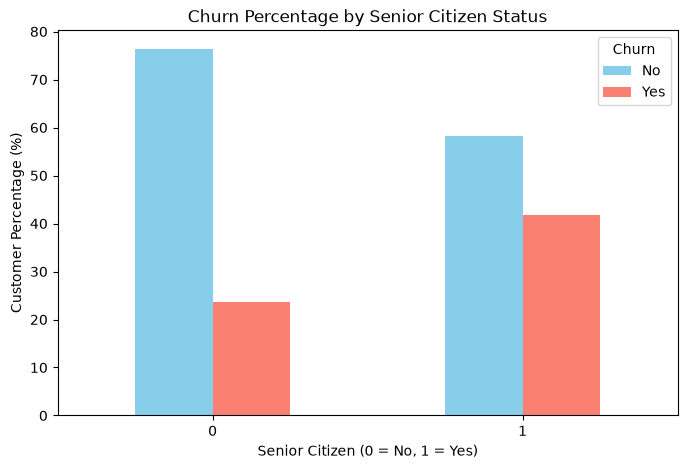

In [372]:
plt.figure(figsize=(8, 5))

ax = senior_churn_percentage.plot(
    kind="bar",
    figsize=(8, 5),
    color=["skyblue", "salmon"]
)

plt.title("Churn Percentage by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Customer Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

In [373]:
df.select_dtypes(include=["int64", "float64"]).columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [374]:
# Create a temporary copy
corr_df = df.copy()

# Convert Churn into numerical values
corr_df["Churn_Encoded"] = corr_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Select numerical columns
numeric_df = corr_df.select_dtypes(include=["int64", "float64"])

# Calculate correlation
correlation_matrix = numeric_df.corr()

correlation_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_Encoded
SeniorCitizen,1.000000,0.016567,0.220173,0.103006,0.150889
tenure,0.016567,1.000000,0.247900,0.826178,-0.352229
MonthlyCharges,0.220173,0.247900,1.000000,0.651174,0.193356
TotalCharges,0.103006,0.826178,0.651174,1.000000,-0.198324
Churn_Encoded,0.150889,-0.352229,0.193356,-0.198324,1.000000


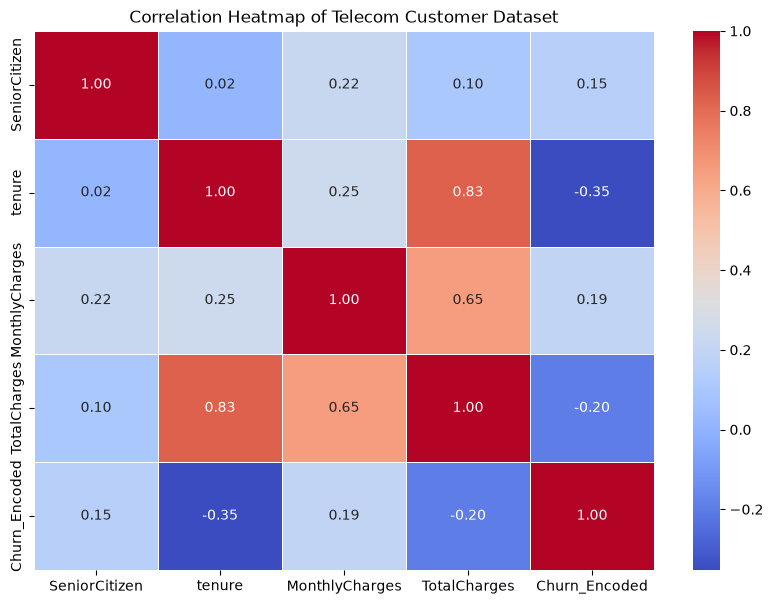

In [375]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Telecom Customer Dataset")

plt.show()

In [376]:
churn_correlation = correlation_matrix["Churn_Encoded"].sort_values(
    ascending=False
)

print(churn_correlation)

Churn_Encoded     1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.198324
tenure           -0.352229
Name: Churn_Encoded, dtype: float64


In [377]:
insights = pd.DataFrame({
    "Analysis": [
        "Overall Churn",
        "Gender",
        "Contract Type",
        "Tenure",
        "Monthly Charges",
        "Internet Service",
        "Payment Method",
        "Senior Citizen",
        "Correlation"
    ],
    "Business Focus": [
        "Reduce overall customer churn",
        "Compare churn across genders",
        "Encourage long-term contracts",
        "Improve new customer retention",
        "Review pricing plans",
        "Improve internet service quality",
        "Promote convenient payment options",
        "Improve customer support",
        "Identify important churn-related variables"
    ]
})

insights

,Analysis,Business Focus
0,Overall Churn,Reduce overall customer churn
1,Gender,Compare churn across genders
2,Contract Type,Encourage long-term contracts
3,Tenure,Improve new customer retention
4,Monthly Charges,Review pricing plans
5,Internet Service,Improve internet service quality
6,Payment Method,Promote convenient payment options
7,Senior Citizen,Improve customer support
8,Correlation,Identify important churn-related variables
